In [1]:
import pandas as pd
df = pd.read_csv("NGCC_Uncertainty_dataset.csv")

In [2]:
df

,Ambient Air Temperature (Dry Bulb Average) (°F),Natural Gas Cost ($/mscf),Cooling Water Temperature Rise (°F),Absorber CO2 Removal Efficiency (%),Amine Scrubber Power Requirement (% MWg),Important Performance and Cost Factors: CO2 Removed (tons/hr),Important Performance and Cost Factors: Net Electrical Output (MW),Costs of CO2 Avoided & Captured: Cost of CO2 Captured ($/ton),Makeup Water (tons/hr)
0,75.137497,6.725,33.900002,60.674999,4.4425,135.200363,491.935730,328.892700,0.000000
1,69.612503,5.875,43.700001,81.525002,5.9275,182.987564,477.473724,228.331604,0.000000
2,84.912498,11.325,33.299999,61.875000,1.6525,136.096603,499.090912,449.124939,0.000000
3,54.737499,2.425,15.300000,82.724998,5.5225,189.321732,489.426849,159.739182,789.642822
4,18.187500,8.875,36.099998,63.375000,1.7425,151.950363,547.840698,362.821564,625.265442
...,...,...,...,...,...,...,...,...,...
195,75.987503,9.025,11.700000,68.025002,2.8225,151.407898,496.516418,361.050995,882.480652
196,59.837502,9.875,32.700001,81.224998,6.3325,184.661026,482.363220,311.367065,199.811310
197,97.237503,9.725,19.100000,64.724998,5.4325,140.030426,469.309143,394.297119,0.000000
198,57.287498,3.975,12.700000,62.174999,9.3475,141.821533,477.319916,253.032211,772.738037


In [3]:
df.isna().sum()

Ambient Air Temperature (Dry Bulb Average) (°F)                       0
Natural Gas Cost ($/mscf)                                             0
Cooling Water Temperature Rise (°F)                                   0
Absorber CO2 Removal Efficiency (%)                                   0
Amine Scrubber Power Requirement (% MWg)                              0
Important Performance and Cost Factors: CO2 Removed (tons/hr)         0
Important Performance and Cost Factors: Net Electrical Output (MW)    0
Costs of CO2 Avoided & Captured: Cost of CO2 Captured ($/ton)         0
Makeup Water (tons/hr)                                                0
dtype: int64

In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
x = df[['Ambient Air Temperature (Dry Bulb Average) (°F)',
    'Natural Gas Cost ($/mscf)',
    'Cooling Water Temperature Rise (°F)',
    'Absorber CO2 Removal Efficiency (%)',
    'Amine Scrubber Power Requirement (% MWg)']]

y = df['Important Performance and Cost Factors: Net Electrical Output (MW)']

In [6]:
x

,Ambient Air Temperature (Dry Bulb Average) (°F),Natural Gas Cost ($/mscf),Cooling Water Temperature Rise (°F),Absorber CO2 Removal Efficiency (%),Amine Scrubber Power Requirement (% MWg)
0,75.137497,6.725,33.900002,60.674999,4.4425
1,69.612503,5.875,43.700001,81.525002,5.9275
2,84.912498,11.325,33.299999,61.875000,1.6525
3,54.737499,2.425,15.300000,82.724998,5.5225
4,18.187500,8.875,36.099998,63.375000,1.7425
...,...,...,...,...,...
195,75.987503,9.025,11.700000,68.025002,2.8225
196,59.837502,9.875,32.700001,81.224998,6.3325
197,97.237503,9.725,19.100000,64.724998,5.4325
198,57.287498,3.975,12.700000,62.174999,9.3475


In [7]:
y

0      491.935730
1      477.473724
2      499.090912
3      489.426849
4      547.840698
          ...    
195    496.516418
196    482.363220
197    469.309143
198    477.319916
199    512.005310
Name: Important Performance and Cost Factors: Net Electrical Output (MW), Length: 200, dtype: float64

In [8]:
from sklearn.model_selection import GridSearchCV, train_test_split, RandomizedSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
from sklearn.ensemble import GradientBoostingRegressor

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print("\n=== SHAP MODEL ===\n")


=== SHAP MODEL ===



In [9]:
# Gradient Boosting Regressor
gbr_grid = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    {
        "n_estimators": [100, 300],
        "max_depth": [3, 6, 10],
        "learning_rate": [0.01, 0.1, 0.3],
        "subsample": [0.8, 1.0],
        "max_features": [0.8, 1.0]
    },
    cv=5, scoring="r2", n_jobs=-1
)
gbr_grid.fit(x_train, y_train)

best_gbr = gbr_grid.best_estimator_
print("Gradient Boosting best params:", gbr_grid.best_params_)
print('Train R2:', best_gbr.score(x_train, y_train))
print('Test R2:', best_gbr.score(x_test, y_test))

Gradient Boosting best params: {'learning_rate': 0.1, 'max_depth': 3, 'max_features': 0.8, 'n_estimators': 300, 'subsample': 0.8}
Train R2: 0.9999800327687199
Test R2: 0.9894756550276593


In [10]:
#Checking the RMSE and MAPE scores
from sklearn.metrics import mean_squared_error
import numpy as np

print("\n=== RMSE & MAPE ===\n")

models = {
    'Gradient Boost':    best_gbr
}

for name, model in models.items():
    y_pred = model.predict(x_test)
    rmse   = np.sqrt(mean_squared_error(y_test, y_pred))
    mape   = np.mean(np.abs((y_test - y_pred) / y_test)) * 100
    print(f"{name} | RMSE: {rmse:.4f} | MAPE: {mape:.4f}%")


=== RMSE & MAPE ===

Gradient Boost | RMSE: 2.4324 | MAPE: 0.3875%


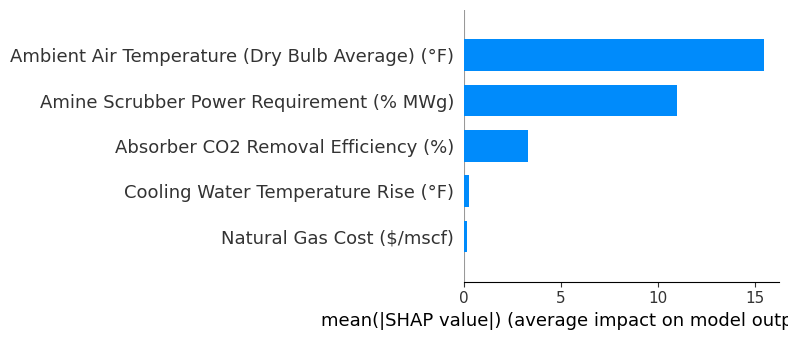

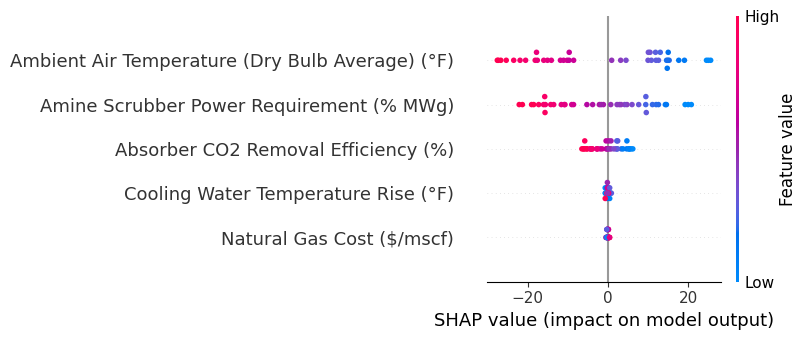

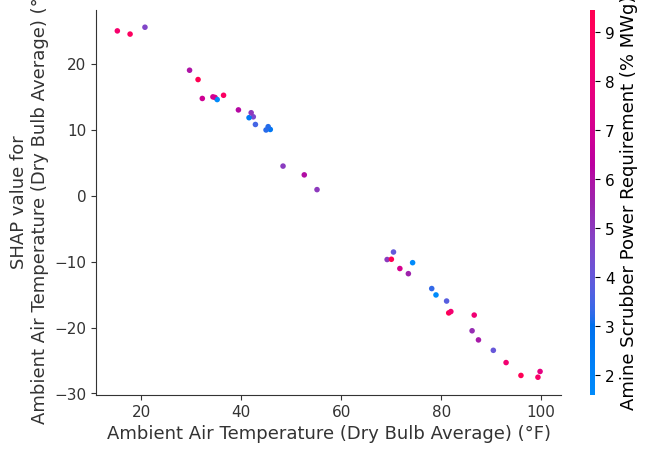

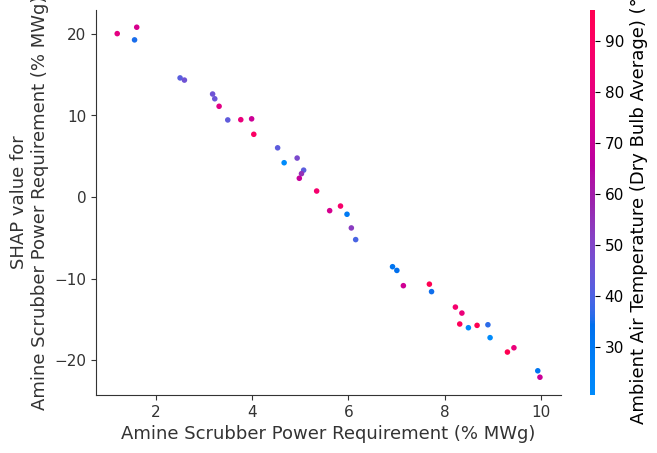

In [11]:
import shap, numpy as np
explainer   = shap.TreeExplainer(best_gbr)
shap_values = explainer.shap_values(x_test)

shap.summary_plot(shap_values, x_test, plot_type="bar")
shap.summary_plot(shap_values, x_test)

mean_abs = np.abs(shap_values).mean(axis=0)
order    = np.argsort(mean_abs)[::-1]
for i in order[:2]:
    shap.dependence_plot(x_test.columns[i], shap_values, x_test)